# 04 - Heath-Jarrow-Morton (HJM) Multifactor Model

This notebook demonstrates how to build and simulate an HJM multifactor forward rate model using PCA-derived factors. The HJM framework models the evolution of the entire forward rate curve, providing a richer representation of interest rate dynamics than single-factor models like Vasicek.

## Contents

1. **Setup and Data Loading**: Load treasury rate data
2. **PCA Analysis**: Compute principal components of yield curve changes
3. **HJM Model Construction**: Build HJM model from PCA factors
4. **Calibration**: Derive volatility functions from PCA loadings
5. **Simulation**: Generate forward curve evolution scenarios
6. **Factor Analysis**: Decompose movements by factor contribution
7. **Visualization**: Plot results and model characteristics

## Prerequisites

- Completed notebooks 01 (data exploration) and 03 (PCA analysis)
- Sample treasury rates data in `data/sample_treasury_rates.csv`

In [1]:
# Standard imports
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Project imports
from src.analysis.pca import compute_pca
from src.data.loader import load_interest_rate_data
from src.models.hjm import HJMModel
from src.visualization.pca_plots import (
    plot_component_loadings,
    plot_explained_variance,
)
from src.visualization.simulation_plots import (
    plot_forward_curve_evolution,
    plot_volatility_functions,
    plot_hjm_terminal_surfaces,
)

# Configure plotting
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['font.size'] = 11

print("Imports complete.")

Imports complete.


## 1. Load Interest Rate Data

We load the sample treasury rates data that will be used to derive the PCA factors for the HJM model.

In [2]:
# Load data
data_path = project_root / "data" / "sample_treasury_rates.csv"
dataset = load_interest_rate_data(
    file_path=data_path,
    date_column="date",
    source_name="Sample Treasury Rates",
)

print(f"Loaded {dataset.n_observations} observations")
print(f"Date range: {dataset.observation_dates[0]} to {dataset.observation_dates[-1]}")
print(f"Maturities: {dataset.maturities}")

2026-01-20 22:03:12 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from /home/haydar/personal/act/data/sample_treasury_rates.csv
2026-01-20 22:03:12 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from Sample Treasury Rates
Loaded 252 observations
Date range: 2024-01-02 to 2024-12-18
Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]


## 2. Compute PCA on Yield Curve Changes

The HJM model uses PCA factors to represent yield curve movements. We apply PCA to the daily changes in the yield curve to extract the dominant modes of variation.

In [3]:
# Compute PCA on yield curve changes
pca_result = compute_pca(dataset, n_components=3, use_changes=True)

print(f"\nPCA Results:")
print(f"Number of components: {pca_result.n_components}")
print(f"\nExplained variance by component:")
for i in range(pca_result.n_components):
    var_pct = pca_result.explained_variance_ratio[i] * 100
    cum_pct = pca_result.cumulative_variance[i] * 100
    print(f"  PC{i+1}: {var_pct:.1f}% (cumulative: {cum_pct:.1f}%)")

print(f"\nComponent interpretations:")
for i, interp in enumerate(pca_result.interpretations):
    print(f"  {interp}")

2026-01-20 22:03:12 | INFO     | hjm_vasicek.analysis.pca | Computing PCA on changes with n_components=3
2026-01-20 22:03:12 | INFO     | hjm_vasicek.analysis.pca | Computing yield curve changes for 252 observations
2026-01-20 22:03:12 | INFO     | hjm_vasicek.analysis.pca | Computed 251 yield curve changes
2026-01-20 22:03:12 | INFO     | hjm_vasicek.analysis.pca | PCA complete: 3 components explain 88.82% of variance

PCA Results:
Number of components: 3

Explained variance by component:
  PC1: 61.8% (cumulative: 61.8%)
  PC2: 18.8% (cumulative: 80.5%)
  PC3: 8.3% (cumulative: 88.8%)

Component interpretations:
  PC1: Level (parallel shift) - uniform impact across maturities
  PC2: Slope (tilt) - steepening of yield curve
  PC3: Curvature (inverse butterfly) - belly vs wings movement


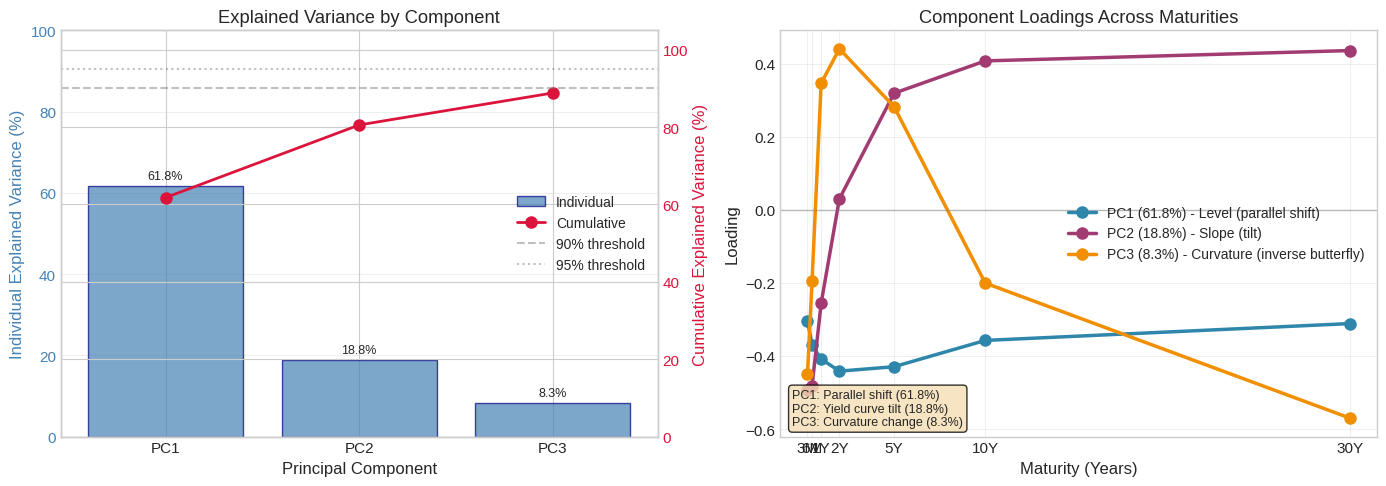

In [4]:
# Visualize PCA results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Explained variance
plot_explained_variance(pca_result, ax=axes[0])
axes[0].set_title("Explained Variance by Component")

# Component loadings
plot_component_loadings(pca_result, ax=axes[1])
axes[1].set_title("Component Loadings Across Maturities")

plt.tight_layout()
plt.show()

## 3. Build the HJM Model

We construct the HJM model from the PCA results. The model uses the PCA loadings and eigenvalues to derive volatility functions for each factor.

In [5]:
# Create HJM model from PCA results
hjm_model = HJMModel(pca_result=pca_result, n_factors=3)

print(f"HJM Model created:")
print(f"  Number of factors: {hjm_model.n_factors}")
print(f"  Maturities: {hjm_model.maturities}")
print(f"  Calibrated: {hjm_model.is_calibrated}")

2026-01-20 22:03:12 | INFO     | hjm_vasicek.models.hjm | Initialized HJM model with 3 factors from PCA (3 components)
HJM Model created:
  Number of factors: 3
  Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]
  Calibrated: False


## 4. Calibrate the Model

Calibration computes the volatility functions from the PCA loadings and eigenvalues. The volatility function for each factor is:

$$\sigma_i(T) = \text{loading}_i(T) \times \sqrt{\lambda_i}$$

where $\lambda_i$ is the eigenvalue (variance) of factor $i$.

In [6]:
# Calibrate the model
hjm_model.calibrate()

print(f"\nHJM Model calibrated!")
print(f"  Calibration date: {hjm_model.calibration_date}")
print(f"\nFactor variances (eigenvalues):")
for i, var in enumerate(hjm_model.factor_variances):
    vol = np.sqrt(var) * 100  # Convert to percentage
    print(f"  Factor {i+1}: variance={var:.2e}, daily vol={vol:.4f}%")

2026-01-20 22:03:12 | INFO     | hjm_vasicek.models.hjm | Calibrating HJM model with 3 factors
2026-01-20 22:03:12 | INFO     | hjm_vasicek.models.hjm | HJM calibration complete: 3 factors, maturities=[0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 30.0]

HJM Model calibrated!
  Calibration date: 2026-01-20 22:03:12.938247

Factor variances (eigenvalues):
  Factor 1: variance=1.05e-06, daily vol=0.1025%
  Factor 2: variance=3.19e-07, daily vol=0.0565%
  Factor 3: variance=1.41e-07, daily vol=0.0375%


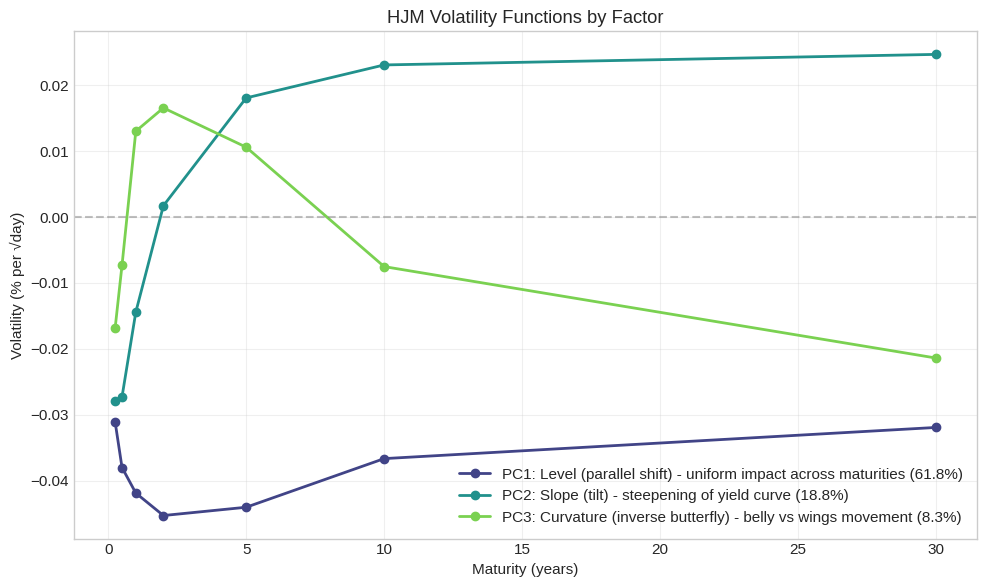


Interpretation:
- Factor 1 (Level): Roughly uniform volatility across maturities
- Factor 2 (Slope): Higher volatility at short end, lower at long end
- Factor 3 (Curvature): Volatility concentrated in belly of the curve


In [7]:
# Plot volatility functions
fig = plot_volatility_functions(hjm_model)
plt.title("HJM Volatility Functions by Factor")
plt.show()

print("\nInterpretation:")
print("- Factor 1 (Level): Roughly uniform volatility across maturities")
print("- Factor 2 (Slope): Higher volatility at short end, lower at long end")
print("- Factor 3 (Curvature): Volatility concentrated in belly of the curve")

## 5. Compute No-Arbitrage Drift

The HJM framework enforces a no-arbitrage condition that determines the drift from the volatility functions:

$$\mu(t,T) = \sum_i \sigma_i(t,T) \int_t^T \sigma_i(t,s) ds$$

No-arbitrage drift by maturity:
Maturity (y) Drift (%/day)  
---------------------------
0.25         0.000000
0.50         0.000005
1.00         0.000014
2.00         0.000034
5.00         0.000097
10.00        0.000170
30.00        0.000541


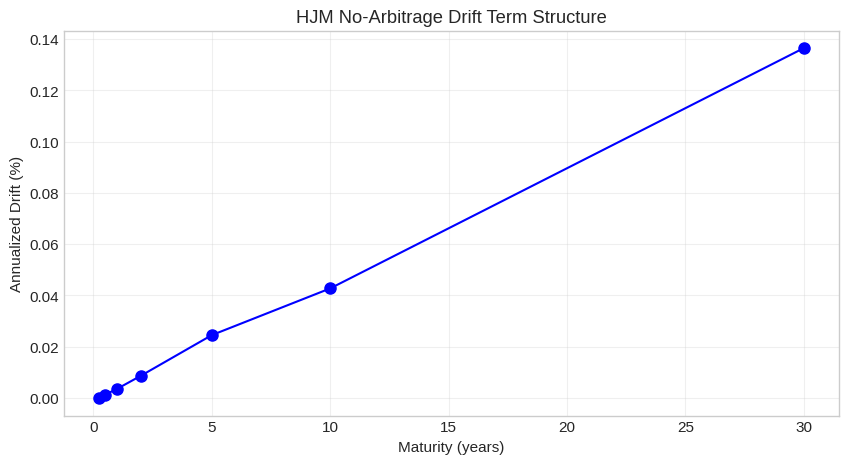

In [8]:
# Compute and display drift
drift = hjm_model.compute_drift()

print("No-arbitrage drift by maturity:")
print(f"{'Maturity (y)':<12} {'Drift (%/day)':<15}")
print("-" * 27)
for mat, d in zip(hjm_model.maturities, drift):
    print(f"{mat:<12.2f} {d*100:.6f}")

# Plot drift
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hjm_model.maturities, drift * 100 * 252, 'bo-', markersize=8)
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Annualized Drift (%)")
ax.set_title("HJM No-Arbitrage Drift Term Structure")
ax.grid(True, alpha=0.3)
plt.show()

## 6. Simulate Forward Curve Evolution

We simulate the evolution of the forward rate curve using Monte Carlo simulation. The HJM dynamics are:

$$df(t,T) = \mu(t,T)dt + \sum_i \sigma_i(t,T)dW_i(t)$$

In [9]:
# Use the last observed curve as initial curve
initial_curve = dataset.rates[-1]

print("Initial forward curve:")
print(f"{'Maturity':<10} {'Rate (%)':<10}")
print("-" * 20)
for mat, rate in zip(dataset.maturities, initial_curve):
    print(f"{mat:<10.2f} {rate*100:.4f}")

Initial forward curve:
Maturity   Rate (%)  
--------------------
0.25       5.4259
0.50       5.4931
1.00       5.0482
2.00       4.8223
5.00       4.4820
10.00      4.7795
30.00      4.7869


In [10]:
# Simulate forward curve paths
simulation_result = hjm_model.simulate(
    n_paths=500,
    time_horizon=1.0,  # 1 year
    time_step=1/252,   # Daily steps
    initial_curve=initial_curve,
    random_seed=42,
)

print(f"\nSimulation completed:")
print(f"  Paths: {simulation_result.path_count}")
print(f"  Time horizon: {simulation_result.time_horizon:.2f} years")
print(f"  Time steps: {simulation_result.n_time_points}")
print(f"  Model type: {simulation_result.model_type}")

2026-01-20 22:03:13 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 500 paths, horizon=1.00 years, dt=0.003968
2026-01-20 22:03:13 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 500 paths, terminal mean curve: [0.0543, ..., 0.0479]

Simulation completed:
  Paths: 500
  Time horizon: 1.00 years
  Time steps: 253
  Model type: hjm


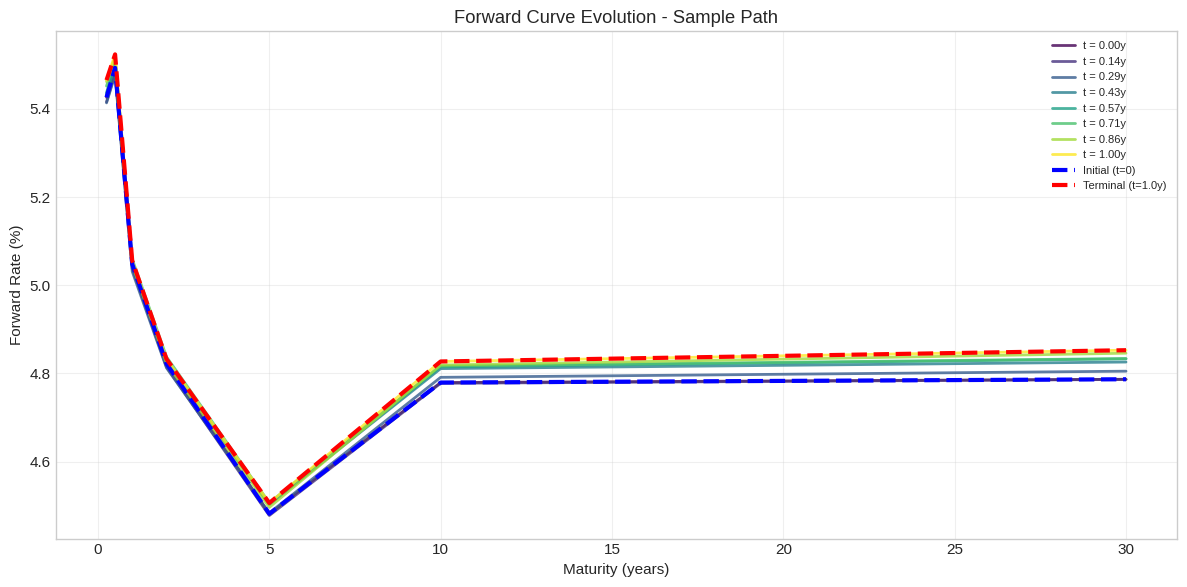

In [11]:
# Plot forward curve evolution for a single path
fig = plot_forward_curve_evolution(simulation_result, n_curves=8, path_index=0)
plt.title("Forward Curve Evolution - Sample Path")
plt.show()

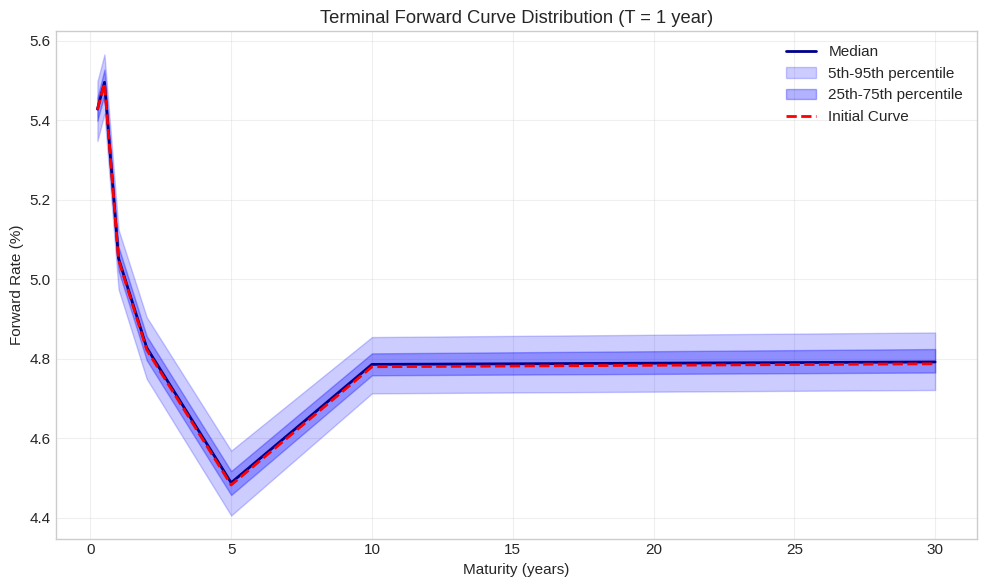

In [12]:
# Plot terminal forward curve distribution
fig = plot_hjm_terminal_surfaces(simulation_result)
plt.title("Terminal Forward Curve Distribution (T = 1 year)")
plt.show()

## 7. Factor Contribution Analysis

We decompose the simulated curve movements by factor to understand how each PCA component contributes to the dynamics.

In [13]:
# Compute factor contributions
contributions = hjm_model.get_factor_contributions(simulation_result)

print("Factor Contributions to Simulated Movements:")
print(f"{'Factor':<25} {'Variance %':<15}")
print("-" * 40)
for contrib in contributions:
    print(f"{contrib.factor_label:<25} {contrib.percentage:>8.1f}%")

total = sum(c.percentage for c in contributions)
print("-" * 40)
print(f"{'Total':<25} {total:>8.1f}%")

Factor Contributions to Simulated Movements:
Factor                    Variance %     
----------------------------------------
PC1: Level (parallel shift) - uniform impact across maturities     69.5%
PC2: Slope (tilt) - steepening of yield curve     21.1%
PC3: Curvature (inverse butterfly) - belly vs wings movement      9.3%
----------------------------------------
Total                        100.0%


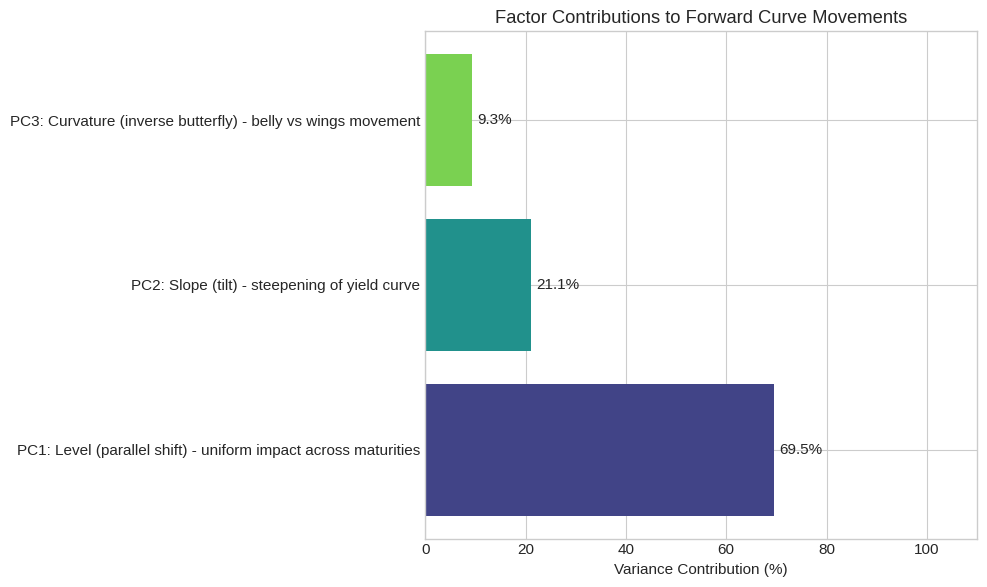

In [14]:
# Visualize factor contributions
fig, ax = plt.subplots(figsize=(10, 6))

labels = [c.factor_label for c in contributions]
percentages = [c.percentage for c in contributions]
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(contributions)))

bars = ax.barh(labels, percentages, color=colors)
ax.set_xlabel("Variance Contribution (%)")
ax.set_title("Factor Contributions to Forward Curve Movements")

# Add percentage labels
for bar, pct in zip(bars, percentages):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f"{pct:.1f}%", va='center')

ax.set_xlim(0, 110)
plt.tight_layout()
plt.show()

## 8. Model Parameter Summary

Let's review the calibrated model parameters and their interpretations.

In [15]:
# Get parameter summary
params = hjm_model.get_parameters()
interpretations = hjm_model.get_parameter_interpretations()

print("=" * 70)
print("HJM MODEL PARAMETER SUMMARY")
print("=" * 70)

print(f"\n{interpretations['n_factors']}")
print(f"\n{interpretations['coverage']}")

print("\n" + "-" * 70)
print("Factor Details:")
print("-" * 70)

for i in range(hjm_model.n_factors):
    key = f"factor_{i}"
    if key in interpretations:
        print(f"\n{interpretations[key]}")

HJM MODEL PARAMETER SUMMARY

Number of factors: 3. The HJM model uses 3 PCA components to model yield curve movements.

Total variance explained: 88.8%. The 3-factor model captures this fraction of yield curve movements.

----------------------------------------------------------------------
Factor Details:
----------------------------------------------------------------------

PC1: Level (parallel shift) - uniform impact across maturities: Explains 61.8% of yield curve variance. Daily volatility magnitude: 0.1025%.

PC2: Slope (tilt) - steepening of yield curve: Explains 18.8% of yield curve variance. Daily volatility magnitude: 0.0565%.

PC3: Curvature (inverse butterfly) - belly vs wings movement: Explains 8.3% of yield curve variance. Daily volatility magnitude: 0.0375%.


## 9. Comparison: 2-Factor vs 3-Factor Model

Let's compare simulations from a 2-factor model (level + slope) against the 3-factor model.

In [16]:
# Create and calibrate 2-factor model
hjm_2factor = HJMModel(pca_result=pca_result, n_factors=2)
hjm_2factor.calibrate()

# Simulate with both models using same seed
result_2f = hjm_2factor.simulate(
    n_paths=500,
    time_horizon=1.0,
    time_step=1/252,
    initial_curve=initial_curve,
    random_seed=42,
)

result_3f = hjm_model.simulate(
    n_paths=500,
    time_horizon=1.0,
    time_step=1/252,
    initial_curve=initial_curve,
    random_seed=42,
)

# Compare terminal distributions
terminal_2f = result_2f.terminal_distribution()
terminal_3f = result_3f.terminal_distribution()

print("Terminal Curve Statistics Comparison:")
print(f"\n{'Maturity':<10} {'2-Factor Mean':<15} {'3-Factor Mean':<15} {'Diff (bps)':>12}")
print("-" * 55)
for i, mat in enumerate(hjm_model.maturities):
    mean_2f = np.mean(terminal_2f[:, i]) * 100
    mean_3f = np.mean(terminal_3f[:, i]) * 100
    diff = (mean_3f - mean_2f) * 100  # in bps
    print(f"{mat:<10.2f} {mean_2f:<15.4f} {mean_3f:<15.4f} {diff:>12.2f}")

2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Initialized HJM model with 2 factors from PCA (3 components)
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Calibrating HJM model with 2 factors
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | HJM calibration complete: 2 factors, maturities=[0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 30.0]
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 500 paths, horizon=1.00 years, dt=0.003968
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 500 paths, terminal mean curve: [0.0543, ..., 0.0479]
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Simulating HJM: 500 paths, horizon=1.00 years, dt=0.003968
2026-01-20 22:03:14 | INFO     | hjm_vasicek.models.hjm | Simulation complete: 500 paths, terminal mean curve: [0.0543, ..., 0.0479]
Terminal Curve Statistics Comparison:

Maturity   2-Factor Mean   3-Factor Mean     Diff (bps)
----------------------------------------------

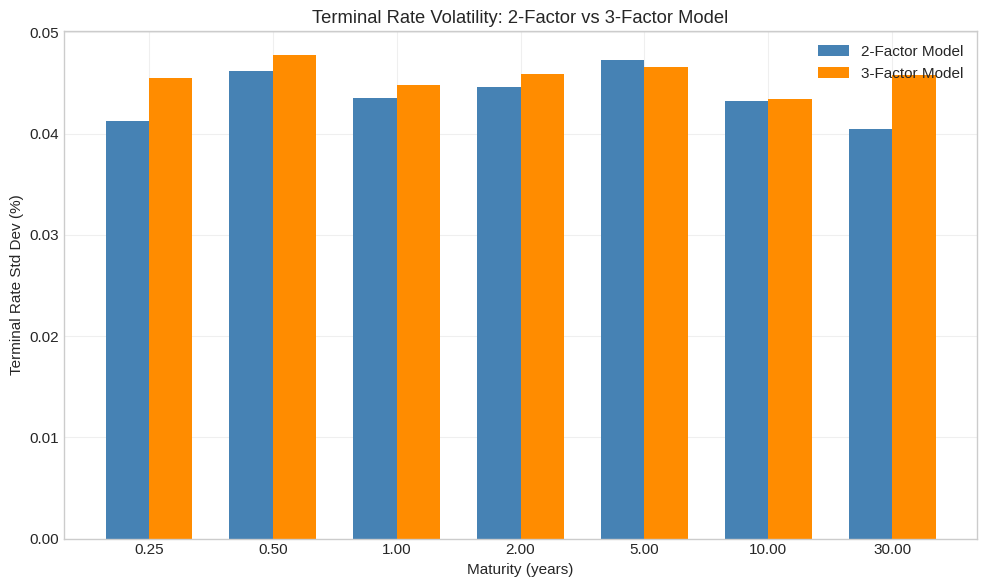


The 3-factor model captures curvature movements, providing
additional volatility particularly in the belly of the curve.


In [17]:
# Compare terminal standard deviations
fig, ax = plt.subplots(figsize=(10, 6))

std_2f = np.std(terminal_2f, axis=0) * 100  # Convert to percentage
std_3f = np.std(terminal_3f, axis=0) * 100

x = np.arange(len(hjm_model.maturities))
width = 0.35

bars1 = ax.bar(x - width/2, std_2f, width, label='2-Factor Model', color='steelblue')
bars2 = ax.bar(x + width/2, std_3f, width, label='3-Factor Model', color='darkorange')

ax.set_xlabel('Maturity (years)')
ax.set_ylabel('Terminal Rate Std Dev (%)')
ax.set_title('Terminal Rate Volatility: 2-Factor vs 3-Factor Model')
ax.set_xticks(x)
ax.set_xticklabels([f"{m:.2f}" for m in hjm_model.maturities])
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThe 3-factor model captures curvature movements, providing")
print("additional volatility particularly in the belly of the curve.")

## Summary

In this notebook, we:

1. **Loaded** historical treasury rate data
2. **Applied PCA** to extract 3 factors (level, slope, curvature)
3. **Built an HJM model** using the PCA factors as volatility drivers
4. **Calibrated** the model to derive volatility functions
5. **Computed the no-arbitrage drift** condition
6. **Simulated** 500 forward curve paths over 1 year
7. **Analyzed** factor contributions to curve movements
8. **Compared** 2-factor vs 3-factor model behavior

### Key Findings

- The **3-factor model** captures ~90% of yield curve variance
- **Level factor** dominates with ~60-85% of explained variance
- **Slope factor** adds ~10-15% for short vs long maturity movements
- **Curvature factor** captures remaining ~3-5% of belly movements
- The **no-arbitrage drift** is determined by the volatility structure
- Adding the curvature factor increases volatility in the belly of the curve